## Exercise 1 : Scale the data


In [27]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [28]:
# 1.
wine_data = pd.read_csv("winequality-white.csv", sep=";")
wine_data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [29]:
# 2.
wine_data.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [30]:
# 3. 
X = wine_data.drop('quality', axis=1)

# 4. 
Y = wine_data['quality']

# 5. 
scaler_standard = StandardScaler()
X_standardized = scaler_standard.fit_transform(X)

# Normalization
scaler_minmax = MinMaxScaler()
X_normalized = scaler_minmax.fit_transform(X)

print("Standardized shape:", X_standardized.shape)
print("Normalized shape:", X_normalized.shape)

Standardized shape: (4898, 11)
Normalized shape: (4898, 11)


In [31]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [32]:
# Features and target
X = wine_data.drop("quality", axis=1)
Y = wine_data["quality"]

# 6. 
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=20)

# 7. 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 8-9. 
model = LinearRegression()

# 10. 
model.fit(X_train_scaled, y_train)

# 11. 
y_pred = model.predict(X_test_scaled)

# 12.
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)
print("R² Score:", r2)

Mean Squared Error: 0.6207195741681918
R² Score: 0.25865427519753437


## Exercise 2 : Prediction pipeline and evaluation

In [ ]:
from sklearn.pipeline import Pipeline

# 1. 
def LR_Pipeline(scaler):
    my_pipeline = Pipeline([
        ("scaler", scaler),
        ("regressor", LinearRegression())
    ])
    return my_pipeline

In [ ]:
# 2.
def evaluate_pipeline(scaler, test_size, random_state=20):
    X_train, X_test, y_train, y_test = train_test_split(
        X, Y, test_size=test_size, random_state=random_state
    )
    pipeline = LR_Pipeline(scaler)
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    return mse, r2, y_test, y_pred, pipeline

# evaluation of result
results = {
    "min-max, test=0.1": evaluate_pipeline(MinMaxScaler(), 0.1),
    "standard, test=0.1": evaluate_pipeline(StandardScaler(), 0.1),
    "min-max, test=0.2": evaluate_pipeline(MinMaxScaler(), 0.2),
    "standard, test=0.2": evaluate_pipeline(StandardScaler(), 0.2),
}

for config, (mse, r2, _, _, _) in results.items():
    print(f"{config} -> MSE: {mse:.3f}, R2: {r2:.3f}")


min-max, test=0.1 -> MSE: 0.642, R2: 0.253
standard, test=0.1 -> MSE: 0.642, R2: 0.253
min-max, test=0.2 -> MSE: 0.621, R2: 0.259
standard, test=0.2 -> MSE: 0.621, R2: 0.259



Best configuration: standard, test=0.2
MSE: 0.6207195741681918
R2: 0.25865427519753437


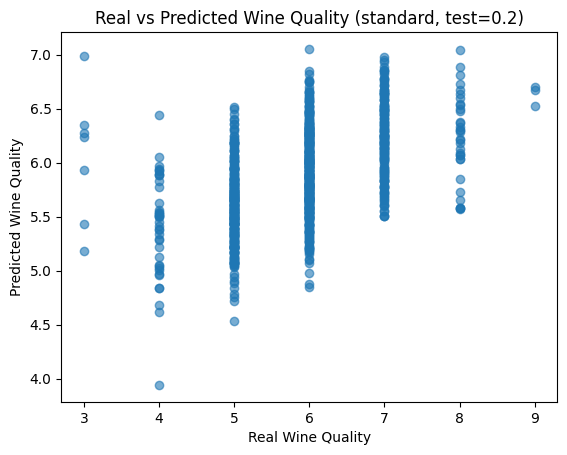

In [45]:
# 3.
import matplotlib.pyplot as plt
best_config = max(results.items(), key=lambda kv: kv[1][1])  
name, (mse, r2, y_test, y_pred, pipeline) = best_config

print("\nBest configuration:", name)
print("MSE:", mse)
print("R2:", r2)

plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Real Wine Quality")
plt.ylabel("Predicted Wine Quality")
plt.title(f"Real vs Predicted Wine Quality ({name})")
plt.show()


In [ ]:
# 4.
predictor = pipeline.named_steps["regressor"]

# Coefficients
coefficients = predictor.coef_
intercept = predictor.intercept_

print("Intercept:", intercept)
print("Coefficients:", coefficients)

# Formula: quality = intercept + Σ θi * feature_i
formula = "quality = {:.3f}".format(intercept)
for feat, coef in zip(X.columns, coefficients):
    formula += f" + ({coef:.3f} * {feat})"
print("\nPredictor formula:\n", formula)


Intercept: 5.889994895354774
Coefficients: [ 0.03824967 -0.1809646   0.00107308  0.39074753 -0.00838017  0.07908096
 -0.02739194 -0.3981574   0.09339981  0.06027215  0.26270551]

Predictor formula:
 quality = 5.890 + (0.038 * fixed acidity) + (-0.181 * volatile acidity) + (0.001 * citric acid) + (0.391 * residual sugar) + (-0.008 * chlorides) + (0.079 * free sulfur dioxide) + (-0.027 * total sulfur dioxide) + (-0.398 * density) + (0.093 * pH) + (0.060 * sulphates) + (0.263 * alcohol)


In [ ]:
# 5.
from sklearn.preprocessing import MinMaxScaler

scaler_y = MinMaxScaler()
Y_scaled = scaler_y.fit_transform(Y.values.reshape(-1, 1)).ravel()

X_train, X_test, y_train, y_test = train_test_split(
    X, Y_scaled, test_size=0.2, random_state=20
)

pipeline_normY = LR_Pipeline(StandardScaler())
pipeline_normY.fit(X_train, y_train)
y_pred = pipeline_normY.predict(X_test)

mse_normY = mean_squared_error(y_test, y_pred)
r2_normY = r2_score(y_test, y_pred)

print("\nWith Y normalized -> MSE:", mse_normY, "R2:", r2_normY)
print("Without normalization -> MSE:", mse, "R2:", r2)



With Y normalized -> MSE: 0.01724221039356088 R2: 0.2586542751975345
Without normalization -> MSE: 0.6207195741681918 R2: 0.25865427519753437


## Exercise 3: Logistic regression

In [ ]:
# 1.
from sklearn.linear_model import LogisticRegression

X = wine_data.drop("quality", axis=1)
y = (wine_data["quality"] > 6).astype(int)

In [ ]:
# 2.
def Reg_Pipeline(scaler, model):
    my_pipeline = Pipeline([
        ("scaler", scaler),
        ("classifier", model)
    ])
    return my_pipeline

In [ ]:
# 3.
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=20
)

# Create pipeline with StandardScaler + Logistic Regression
pipeline = Reg_Pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
pipeline.fit(X_train, y_train)

# Predictions
y_pred = pipeline.predict(X_test)


In [ ]:
# 4.
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
accuracy = accuracy_score(y_test, y_pred)
confusion = confusion_matrix(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Confusion Matrix:\n", confusion)
print("Classification Report:\n", classification_rep)

Accuracy: 0.8183673469387756
Confusion Matrix:
 [[751  30]
 [148  51]]
Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.96      0.89       781
           1       0.63      0.26      0.36       199

    accuracy                           0.82       980
   macro avg       0.73      0.61      0.63       980
weighted avg       0.79      0.82      0.79       980



In [ ]:
# 5.
print("Distribution in full dataset:\n", y.value_counts(normalize=True))
print("Distribution in training set:\n", y_train.value_counts(normalize=True))

Distribution in full dataset:
 quality
0    0.783585
1    0.216415
Name: proportion, dtype: float64
Distribution in training set:
 quality
0    0.780245
1    0.219755
Name: proportion, dtype: float64


## Exercise 4: Naive Bayes classification

In [ ]:
# 1.
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 2.
nb_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', GaussianNB())
])

# 3.
nb_pipeline.fit(X_train, y_train)

# 4.
y_pred = nb_pipeline.predict(X_test)

# 5.
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

print("\nClassification Report:\n", classification_report(y_test, y_pred))

acc = accuracy_score(y_test, y_pred)
print("\nAccuracy:", acc)

Confusion Matrix:
 [[593 188]
 [ 59 140]]

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.76      0.83       781
           1       0.43      0.70      0.53       199

    accuracy                           0.75       980
   macro avg       0.67      0.73      0.68       980
weighted avg       0.81      0.75      0.77       980


Accuracy: 0.7479591836734694


## Exercise 5: performance comparison between different models

AUC Logistic Regression: 0.8053519839916613
AUC Naive Bayes: 0.7898197775046809


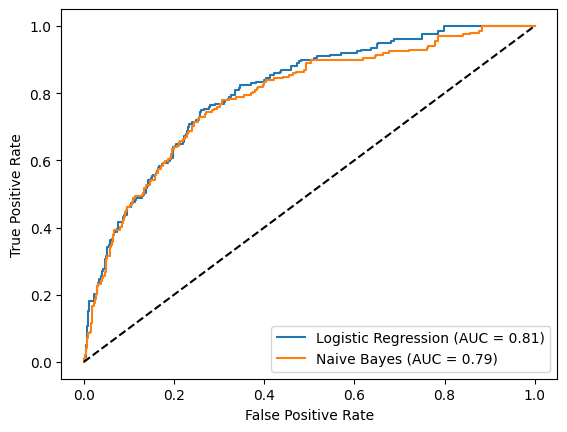

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
# 1.
log_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('log_reg', LogisticRegression(random_state=20))
])

nb_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('nb', GaussianNB())
])

log_pipeline.fit(X_train, y_train)
nb_pipeline.fit(X_train, y_train)

y_proba_log = log_pipeline.predict_proba(X_test)[:,1]
y_proba_nb = nb_pipeline.predict_proba(X_test)[:,1]

# 2.
auc_log = roc_auc_score(y_test, y_proba_log)
auc_nb = roc_auc_score(y_test, y_proba_nb)

print("AUC Logistic Regression:", auc_log)
print("AUC Naive Bayes:", auc_nb)

fpr_log, tpr_log, _ = roc_curve(y_test, y_proba_log)
fpr_nb, tpr_nb, _ = roc_curve(y_test, y_proba_nb)

plt.plot(fpr_log, tpr_log, label=f"Logistic Regression (AUC = {auc_log:.2f})")
plt.plot(fpr_nb, tpr_nb, label=f"Naive Bayes (AUC = {auc_nb:.2f})")
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()
